In [8]:
import pandas as pd
import numpy as np
from scipy.stats import pearsonr, spearmanr
import seaborn as sns
import matplotlib.pyplot as plt

import os
print("Python ищет файлы здесь:", os.getcwd())

'''df = pd.read_excel("data.xlsx")

remove_columns = [
    "Patient No",
    "Sex",
    "Age"
]

df = df.drop(columns=remove_columns, errors="ignore")'''

all_sheets = pd.read_excel("data.xlsx", sheet_name=None)

remove_columns = ["Patient No", "Sex", "Age"]

cleaned_dfs = []
for df in all_sheets.values():
    df_sheet = df.drop(columns=remove_columns, errors="ignore")
    df_sheet.columns = df_sheet.columns.str.strip().str.replace(r'\s+', ' ', regex=True).str.lower()
    
    cleaned_dfs.append(df_sheet)

df = pd.concat(cleaned_dfs, ignore_index=True)

Python ищет файлы здесь: C:\Users\eleon\diplom


In [9]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 34 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   iris stage         120 non-null    int64  
 1   plt                120 non-null    int64  
 2   nlr                120 non-null    float64
 3   mlr                120 non-null    float64
 4   plr                120 non-null    float64
 5   sii                120 non-null    float64
 6   weight (kg)        100 non-null    float64
 7   wbc                120 non-null    float64
 8   neut               120 non-null    float64
 9   lym                120 non-null    float64
 10  mono               120 non-null    float64
 11  eos                113 non-null    float64
 12  baso               113 non-null    float64
 13  luc                113 non-null    float64
 14  rbc                119 non-null    float64
 15  hgb                119 non-null    float64
 16  hct                119 non

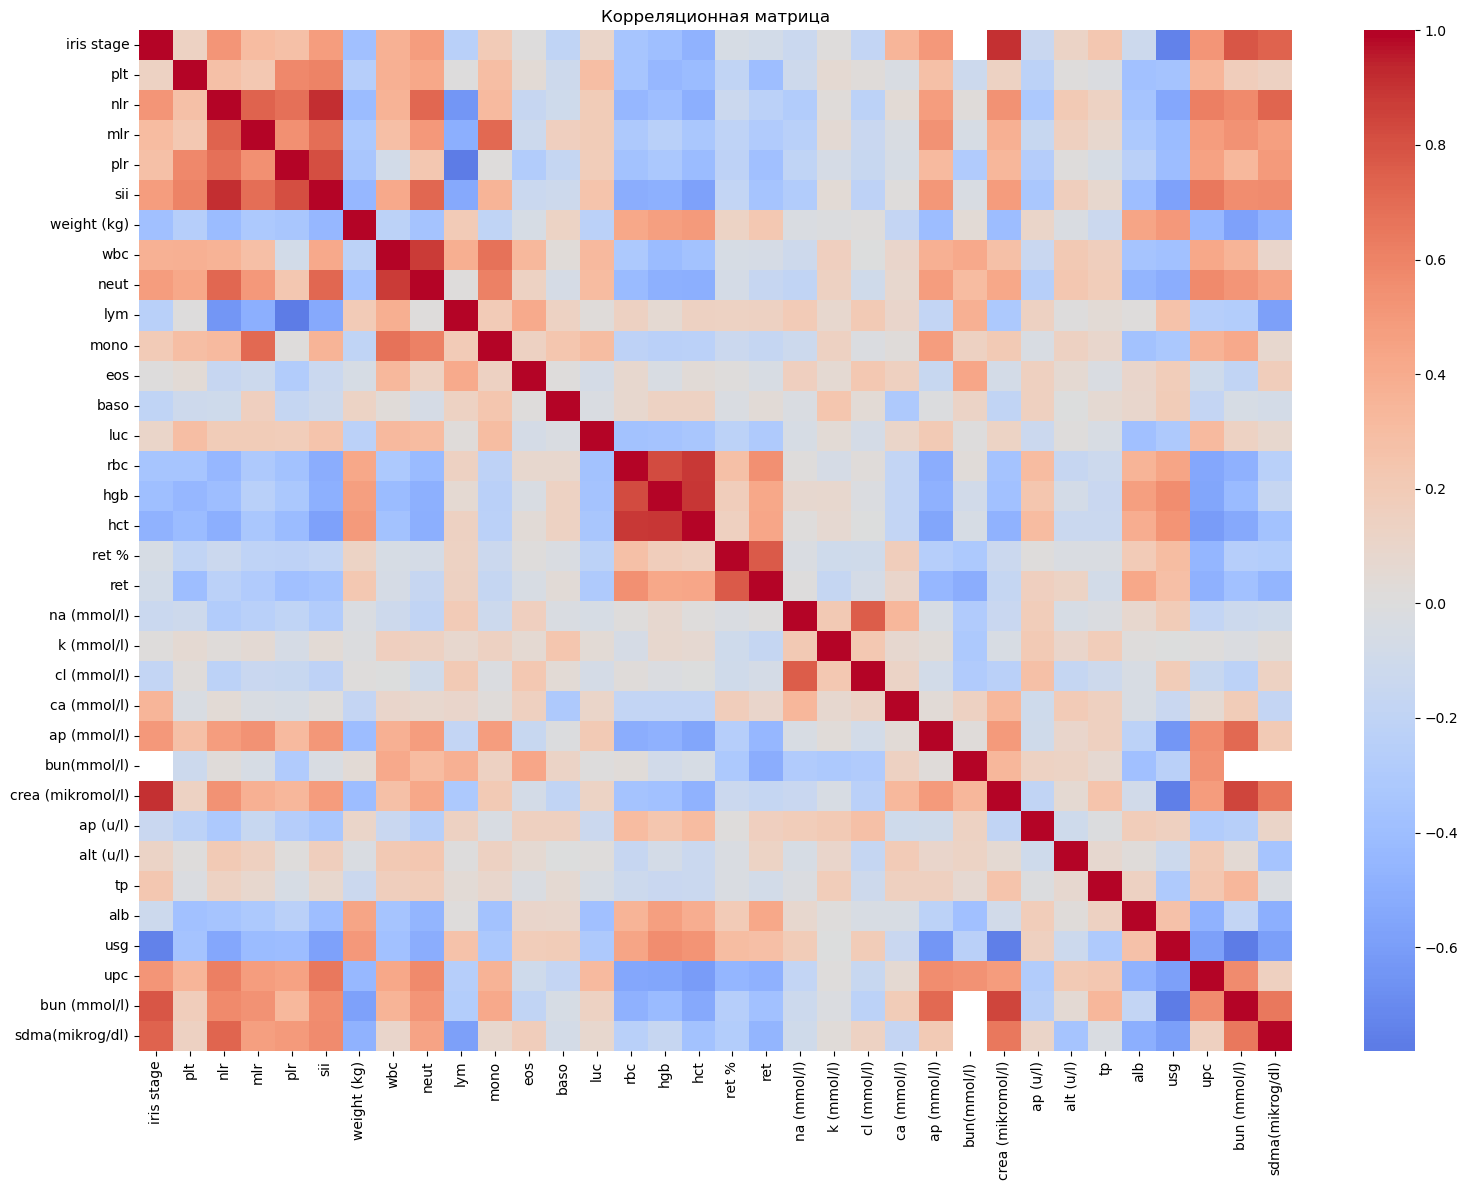

In [13]:
remove_columns = [
    "NLR",
    "MLR",
    "PLR",
    "SII"
]

numeric_df = df.drop(columns=remove_columns, errors="ignore")
numeric_df = numeric_df.select_dtypes(include="number")

plt.figure(figsize=(16, 12))
sns.heatmap(
    numeric_df.corr(method="spearman"),
    cmap="coolwarm",
    center=0,
    annot=False
)

plt.title("Корреляционная матрица")
plt.tight_layout()
plt.show()

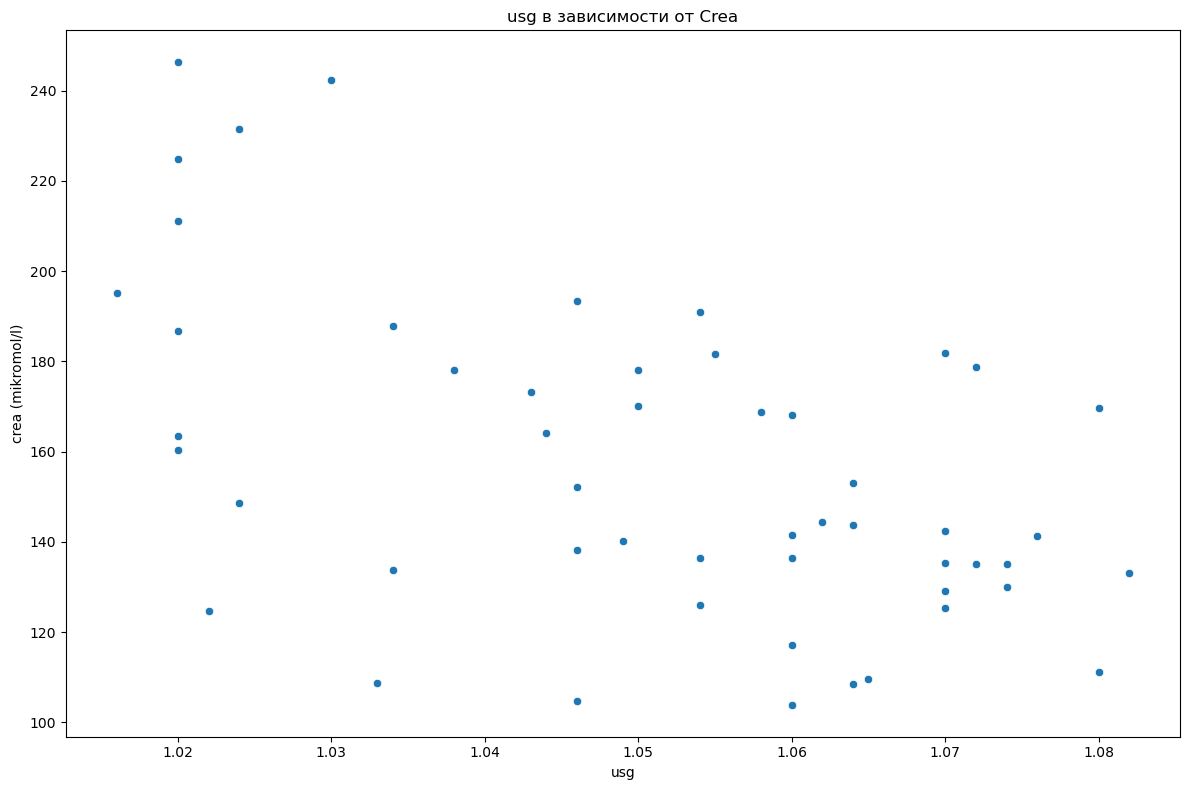

In [20]:
plt.figure(figsize=(12, 8), dpi=100)
filtered_df = filtered_df[
    (filtered_df["crea (mikromol/l)"] < 500) & 
    (filtered_df["usg"] < 1.1)
]
sns.scatterplot(
    data=filtered_df.dropna(subset=["usg", "crea (mikromol/l)"]),
    x="usg",
    y="crea (mikromol/l)"
)

plt.xlabel("usg")
plt.ylabel("crea (mikromol/l)")
plt.title("usg в зависимости от Crea")
plt.tight_layout()
plt.show()